In [6]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "data.py").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

import data

listings = data.load("listings")

print("Dataset shape:", listings.shape)
display(listings.head())

/Users/hyewonerinyoon/Desktop/My Stuff/Projects/SSU Data Dash/SSU-Data-Dash/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset shape: (150000, 22)


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [7]:
print(listings.columns.tolist())

['ml_num', 'sold_price', 'list_price', 'date_listed', 'date_sold', 'days_on_market', 'house_type_name', 'house_style', 'bedrooms', 'washrooms', 'parking_total', 'garage', 'house_area', 'lot_front', 'lot_depth', 'municipality', 'community', 'latitude', 'longitude', 'external_avm_estimate', 'external_avm_estimate_date', 'remarks']


In [8]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   ml_num                      150000 non-null  object        
 1   sold_price                  150000 non-null  float64       
 2   list_price                  150000 non-null  float64       
 3   date_listed                 150000 non-null  datetime64[us]
 4   date_sold                   150000 non-null  datetime64[us]
 5   days_on_market              150000 non-null  int64         
 6   house_type_name             150000 non-null  object        
 7   house_style                 150000 non-null  object        
 8   bedrooms                    150000 non-null  int64         
 9   washrooms                   150000 non-null  int64         
 10  parking_total               150000 non-null  int64         
 11  garage                      150000 non-

In [9]:
missing = listings.isna().sum().sort_values(ascending=False)

display(missing)

lot_depth                     87263
lot_front                     87263
external_avm_estimate          1306
ml_num                            0
sold_price                        0
external_avm_estimate_date        0
longitude                         0
latitude                          0
community                         0
municipality                      0
house_area                        0
garage                            0
parking_total                     0
washrooms                         0
bedrooms                          0
house_style                       0
house_type_name                   0
days_on_market                    0
date_sold                         0
date_listed                       0
list_price                        0
remarks                           0
dtype: int64

### Initial Data Understanding

The dataset contains 150,000 observations and 22 variables, including property characteristics, location information, and housing transaction details.

Missing values were identified in three variables:
- `lot_front`: 58.18% missing
- `lot_depth`: 58.18% missing
- `external_avm_estimate`: 0.87% missing

The high proportion of missing values in lot measurements may be related to property type. Further analysis is needed to determine whether missingness differs across housing categories.

The next steps are to examine missing-value patterns, compare selling prices across property types, and investigate the relationship between house size and selling price.

In [10]:
missing_by_type = (
    listings.groupby("house_type_name")["lot_front"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

display(missing_by_type)

house_type_name
Co-Op Apt             100.0
Condo Apt             100.0
Condo Townhouse       100.0
Detached                0.0
Freehold Townhouse      0.0
Semi-Detached           0.0
Name: lot_front, dtype: float64

In [11]:
price_by_type = (
    listings.groupby("house_type_name")["sold_price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(price_by_type)

,count,median,mean
house_type_name,,,
Detached,43202,1367850.0,1.688778e+06
Semi-Detached,14397,1179100.0,1.322291e+06
Freehold Townhouse,5138,1146600.0,1.283139e+06
Condo Townhouse,10160,786200.0,8.426327e+05
Co-Op Apt,729,646600.0,7.553156e+05
Condo Apt,76374,644300.0,6.990261e+05


In [12]:
print(listings["house_area"].value_counts().head(15))

house_area
700-899      6282
600-799      6101
800-999      4298
900-1099     3934
1000-1199    3714
1100-1299    3648
1200-1399    3426
500-699      3422
1300-1499    3250
1400-1599    2815
1500-1699    2472
1600-1799    2121
1700-1899    1832
1800-1999    1335
1900-2099    1192
Name: count, dtype: int64


### EDA Findings

**1. Missing Values by Property Type**

Lot frontage information is missing for 100% of Co-Op Apartments, Condo Apartments, and Condo Townhouses, while no missing values were found for Detached, Semi-Detached, or Freehold Townhouses. This suggests that missingness is strongly associated with property type rather than occurring randomly.

**2. Selling Prices by Property Type**

Detached houses have the highest median selling price ($1,367,850), followed by Semi-Detached houses ($1,179,100) and Freehold Townhouses ($1,146,600). Condo Apartments have the lowest median price ($644,300).

Mean selling prices exceed median prices across all property types, suggesting positively skewed price distributions.

**3. House Area Data Format**

House area is stored in mixed formats, including exact numerical values and ranges such as "700-899". Converting these values into numerical estimates may help with exploratory analysis and machine learning.

**Potential Modeling Implications**

- Consider property type as a predictive feature.
- Handle missing lot measurements according to property type.
- Convert house area into a numerical feature.
- Evaluate model errors separately for different property types, especially categories with fewer observations.

In [13]:
import numpy as np

def convert_area(value):
    value = str(value).replace("–", "-").strip()

    if "-" in value:
        parts = value.split("-")
        if len(parts) == 2:
            try:
                return (float(parts[0]) + float(parts[1])) / 2
            except ValueError:
                return np.nan

    try:
        return float(value)
    except ValueError:
        return np.nan

listings["area_numeric"] = listings["house_area"].apply(convert_area)

display(listings[["house_area", "area_numeric"]].head(10))

,house_area,area_numeric
0,622,622.0
1,649,649.0
2,900-1099,999.5
3,876,876.0
4,514,514.0
5,1500-1699,1599.5
6,562,562.0
7,1000-1199,1099.5
8,723,723.0
9,1000-1199,1099.5


In [14]:
print("Missing converted areas:", listings["area_numeric"].isna().sum())
print("Correlation:", listings[["area_numeric", "sold_price"]].corr())

Missing converted areas: 0
Correlation:               area_numeric  sold_price
area_numeric      1.000000    0.773166
sold_price        0.773166    1.000000


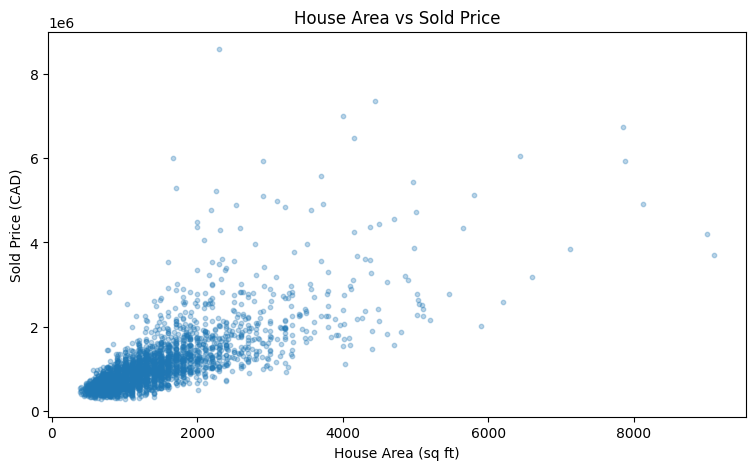

In [15]:
sample = listings.dropna(
    subset=["area_numeric", "sold_price"]
).sample(n=3000, random_state=42)

plt.figure(figsize=(9, 5))

plt.scatter(
    sample["area_numeric"],
    sample["sold_price"],
    alpha=0.3,
    s=10
)

plt.xlabel("House Area (sq ft)")
plt.ylabel("Sold Price (CAD)")
plt.title("House Area vs Sold Price")
plt.show()

### House Area and Selling Price

House area was converted from mixed formats, including exact numerical values and ranges, into a continuous numerical variable using the midpoint of each range. The conversion was successful for all 150,000 observations, with no missing values.

A strong positive correlation was found between house area and selling price (r = 0.7732), suggesting that larger properties generally sell for higher prices.

The scatterplot also shows greater price variability among larger properties, along with several high-priced outliers.

These findings suggest that house area could be an important predictive feature. Further model validation is needed to evaluate its contribution to prediction accuracy.

In [16]:
community_prices = (
    listings.groupby("community")["sold_price"]
    .agg(["count", "median"])
)

# Only communities with at least 100 sales
community_prices = community_prices[
    community_prices["count"] >= 100
]

top10 = community_prices.nlargest(10, "median")

display(top10)

,count,median
community,,
Maplepark,408,3851550.0
Beechcrest,352,3434300.0
Hazelfield,884,2363450.0
Maplemills,477,2134000.0
Maplevale,1234,1961250.0
Poplargardens,665,1807200.0
Rowanhollow,461,1729900.0
Juniperheights,1456,1705750.0
Maplegrove,721,1578800.0


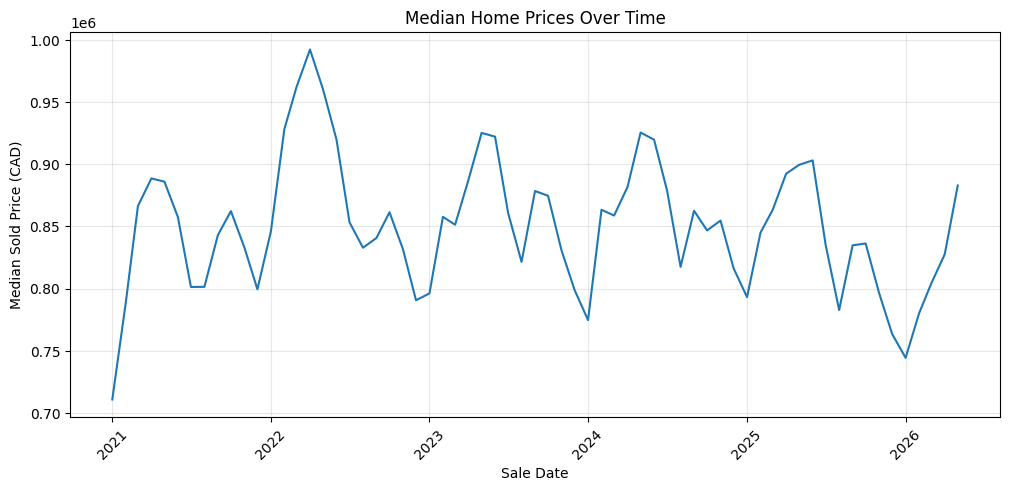

In [17]:
monthly_prices = (
    listings
    .set_index("date_sold")
    .resample("MS")["sold_price"]
    .median()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_prices.index, monthly_prices.values)

plt.title("Median Home Prices Over Time")
plt.xlabel("Sale Date")
plt.ylabel("Median Sold Price (CAD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

### Temporal Trends in Housing Prices

Monthly median selling prices fluctuate considerably between 2021 and 2026, ranging approximately from $710,000 to $990,000.

The highest median price occurs around early 2022, followed by several periods of increases and decreases. Overall, there is no clear consistent upward or downward trend.

These fluctuations may reflect changes in market conditions, seasonal patterns, or differences in the types of properties sold each month.

Since this competition involves predicting future housing prices using historical data, incorporating time-related features may improve model performance. However, their predictive value should be evaluated using time-based validation.